# Long-term stress response
looking back at my proposal defense notes, Freddy and Sarah D. pointed out that a better comparison to pick out the long- and short-term response to stress would be CH vs. HC (instead of HH vs. HC) because these oysters both experienced one stressor but at different time points. 

(But also, couldn't you compare the up- and down-regulated genes of CC vs. HC and CC vs. CH? Because then you'd know the direction of expression, instead of trying to guess if it's up-regulated bc of the most recent exposure or because of long-term response? idk which makes more sense - I suppose I should do both)

## 0. load libraries

In [53]:
library(tidyverse)
library(RColorBrewer)
library(rtracklayer) # for reading GTF file
library(UpSetR)

## 1. read csvs
### DEGs

In [3]:
# get list of files
files <- list.files(
    path = '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs/',
    pattern = '\\.csv$',
    full.names = TRUE
    )

head(files)

[1] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bb_cc.csv"
[2] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_bb.csv"
[3] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_cc.csv"
[4] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_hc.csv"
[5] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_wc.csv"
[6] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bh_bb.csv"

In [5]:
names(files) <- gsub('DEG_', '', tools::file_path_sans_ext(basename(files)))
df_list <- lapply(files, read.csv)
names(df_list)
length(df_list)

[1] "bb_cc"        "bc_bb"        "bc_cc"        "bc_hc"        "bc_wc"       
 [6] "bh_bb"        "bh_bc"        "bh_bw"        "bh_ch"        "bh_hh"       
[11] "bw_bb"        "bw_bc"        "bw_cw"        "bw_ww"        "cb_bb"       
[16] "cb_bc"        "cb_cc"        "cb_ch"        "cb_cw"        "ch_cc"       
[21] "ch_hc"        "cw_cc"        "cw_ch"        "cw_wc"        "hb_bb"       
[26] "hb_bh"        "hb_cb"        "hb_hc"        "hb_hh"        "hb_hw"       
[31] "hc_cc"        "hc_hh"        "hh_cc"        "hh_ch"        "hw_bw"       
[36] "hw_cw"        "hw_hc"        "hw_hh"        "hw_ww"        "vst_filtered"
[41] "wb_bb"        "wb_bw"        "wb_cb"        "wb_hb"        "wb_wc"       
[46] "wb_wh"        "wb_ww"        "wc_cc"        "wc_hc"        "wc_ww"       
[51] "wh_bh"        "wh_ch"        "wh_hh"        "wh_hw"        "wh_wc"       
[56] "wh_ww"        "ww_cc"        "ww_cw"

[1] 58

In [7]:
# only grab the dfs i'm interested in
deg.list <- df_list[c('ch_hc', 'cw_wc', 'cb_bc', 'ch_cc', 'hc_cc', 'cw_cc', 'wc_cc', 'bc_cc', 'cb_cc')]
names(deg.list)

[1] "ch_hc" "cw_wc" "cb_bc" "ch_cc" "hc_cc" "cw_cc" "wc_cc" "bc_cc" "cb_cc"

In [11]:
# combine into one df
deg.df <- bind_rows(deg.list, .id = "comparison")

# rename gene column 
colnames(deg.df)[2] <- 'gene'

head(deg.df)

,comparison,gene,baseMean,log2FoldChange,lfcSE,pvalue,padj,pair,DEG_group
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,ch_hc,LOC144622046,14.97323,-20.863903,3.308651,1.319192e-10,1.370957e-07,HC vs. CH,HC
2,ch_hc,LOC144622060,65.28037,19.692960,3.120874,1.386469e-10,1.385456e-07,HC vs. CH,CH
3,ch_hc,LOC111103137,103.49992,2.980083,2.059201,3.282576e-05,1.349055e-02,HC vs. CH,CH
4,ch_hc,LOC144619407,11.94387,18.554174,3.961737,3.147059e-07,1.739654e-04,HC vs. CH,CH
5,ch_hc,LOC144623974,82.70086,-15.328927,8.816992,2.335978e-05,1.011517e-02,HC vs. CH,HC
6,ch_hc,LOC111104604,153.21759,-23.877694,4.477703,2.636896e-08,1.903033e-05,HC vs. CH,HC


### gene annotations

In [50]:
genes <- as.data.frame(import('/project/pi_sarah_gignouxwolfsohn_uml_edu/Reference_genomes/Cvirginica_genome/new_cvir_genome/GCF_053477285.1_ASM5347728v1_genomic.gff')) %>%
dplyr::select(gene, description) %>% 
na.omit()

head(genes)

,gene,description
,<chr>,<chr>
2,LOC144621260,protein O-mannosyl-transferase TMTC2-like
28,LOC144621269,uncharacterized LOC144621269
63,LOC111120925,mitochondrial amidoxime-reducing component 1-like
79,Trnae-cuc,transfer RNA glutamic acid (anticodon CUC)
82,Trnae-cuc,transfer RNA glutamic acid (anticodon CUC)
85,Trnae-cuc,transfer RNA glutamic acid (anticodon CUC)


## 2. barplot - # of DEGs

pulling out only the comparisons that get at timing (not comparing against CC)

In [34]:
timing.df <- deg.df %>% 
filter(!grepl('cc', comparison)) %>%
mutate(stress_timing = case_when(
    # if C is first, the stress was experienced later/second
    substr(DEG_group, 1, 1) == "C" ~ "second",
    # if C is second, the stress was experienced early/first
    substr(DEG_group, 2, 2) == "C" ~ "first"
  ))

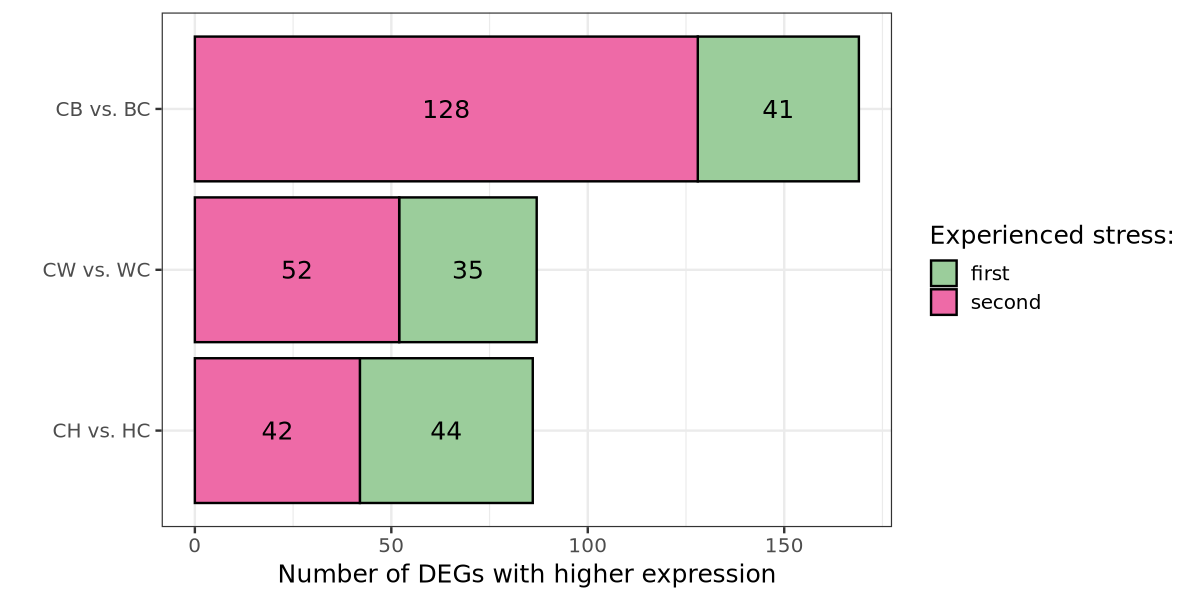

In [46]:
options(repr.plot.height = 5, repr.plot.width = 10)

ggplot(timing.df, aes(x = fct_rev(fct_infreq(comparison)), fill = stress_timing)) +
geom_bar(col = 'black') +
  geom_text(stat = "count",
            aes(label = after_stat(count), group = stress_timing),
            position = position_stack(vjust = 0.5)) +
theme_bw(base_size = 15) +
coord_flip() +
scale_x_discrete(labels = c(
    ch_hc = "CH vs. HC",
    cw_wc = "CW vs. WC",
    cb_bc = "CB vs. BC"
  )) +
scale_fill_manual(values = c('darkseagreen3', 'hotpink2')) +
labs(x = '',
    y = 'Number of DEGs with higher expression',
     fill = 'Experienced stress:')

so we mainly see higher expression of DEGs in the oyster that experienced the stress later in life (so higher expression in CB over BC) - this isn't true for CH vs. HC (it's about even)

## 3. upset plot

In [56]:
# one vector of genes per comparison
gene.list <- split(deg.df$gene, deg.df$comparison)

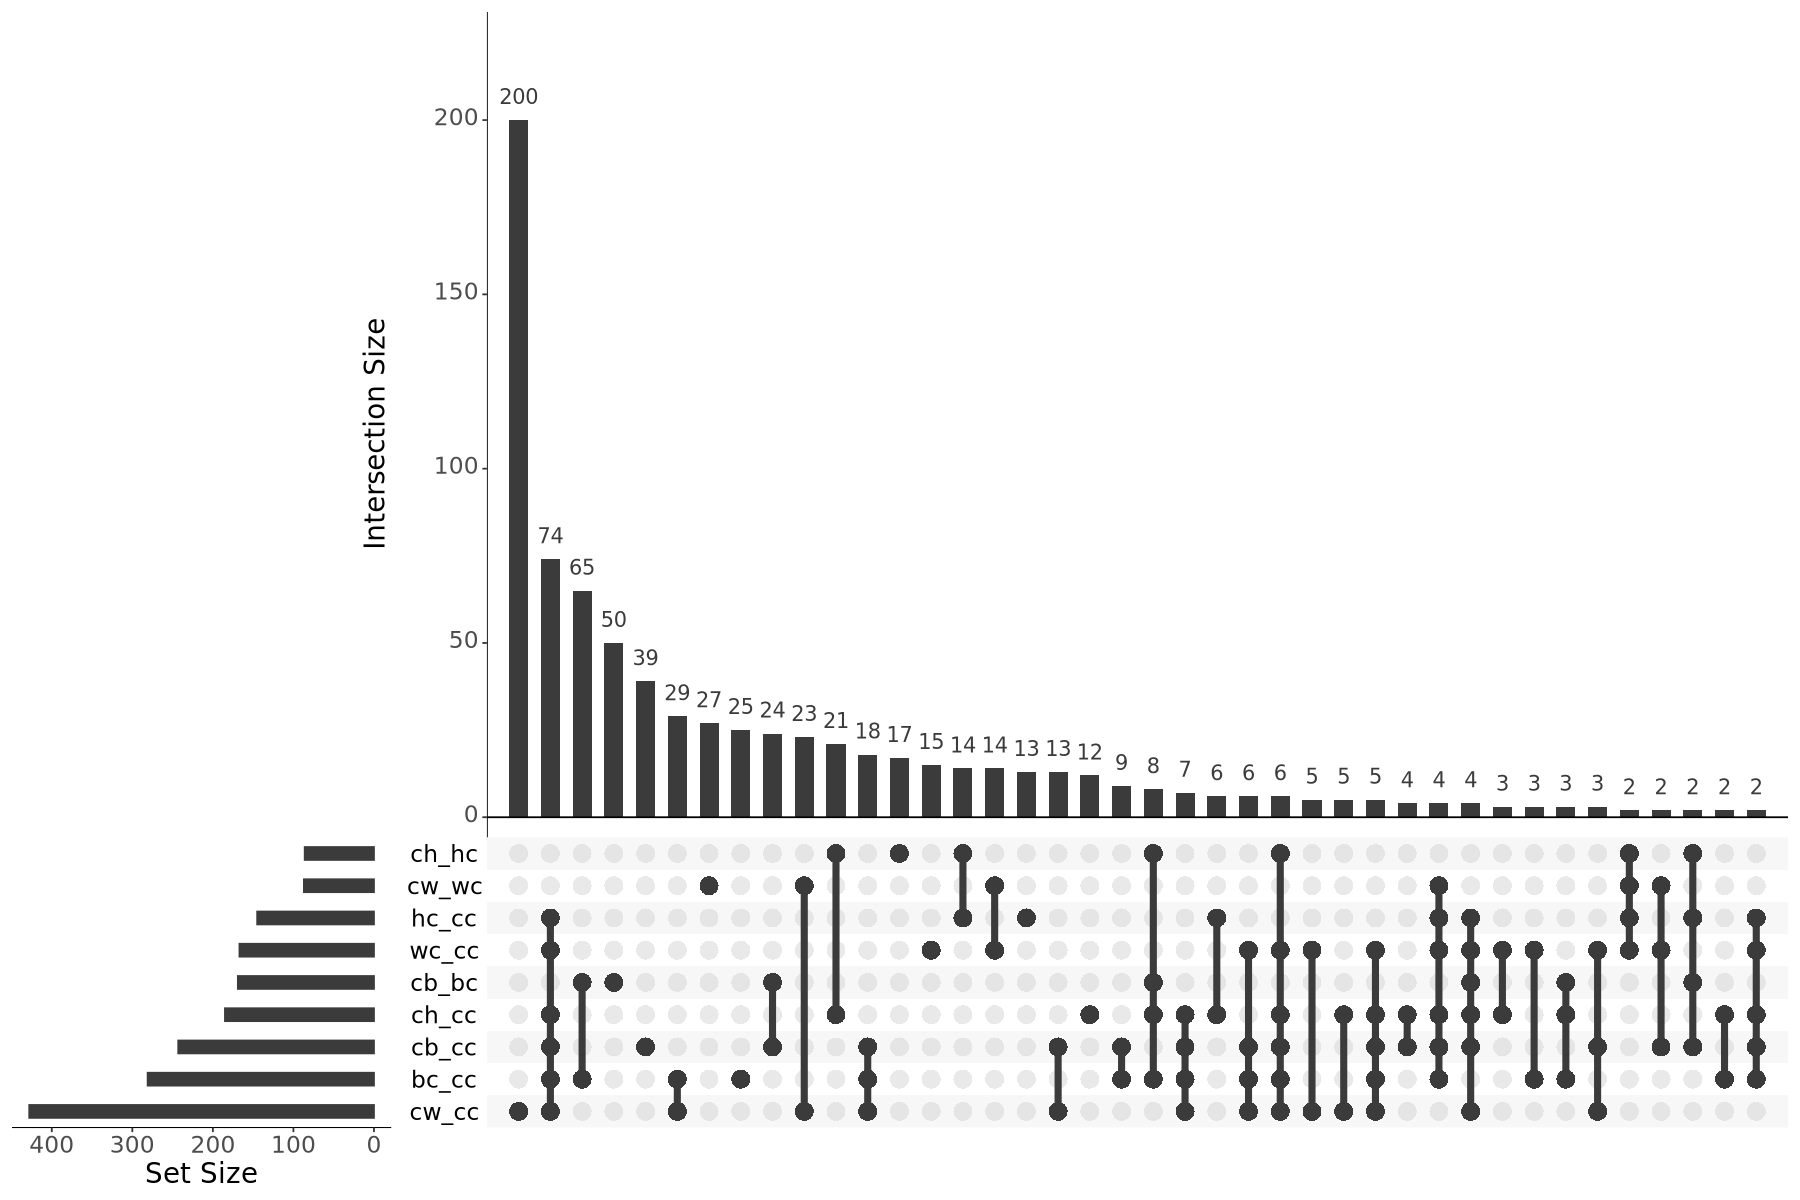

In [61]:
options(repr.plot.height = 10, repr.plot.width = 15)

upset(fromList(gene.list), 
      keep.order=TRUE,
      nsets = length(gene.list),
      point.size = 5, 
      line.size = 2,
      order.by = "freq",
         text.scale = c(2, 2, 2, 2, 2, 2))


doesn't look like there's any shared DEGs among CH vs. HC, CW vs. WC, and CB vs. BC - so no shared long-term stress-response genes among different environmental treatments

The most shared DEGs (74) are shared between all comparisons with CC, regardless of when the stress was experienced (which is what I've seen before; all of the stressed oysters only experienced stress at one timepoint) - this suggests a shared/general response to stress (but again, I've already looked at that in [this code](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase2_v_phase2/upset_p2.v.p2.ipynb))